# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Волошин Михайло

**Група:** 4-9

**Дата:** 26.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [ ]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [ ]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print("x_train:", x_train.shape, x_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("x_test: ", x_test.shape, x_test.dtype)
print("y_test: ", y_test.shape, y_test.dtype)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train: (60000, 28, 28) uint8
y_train: (60000,) uint8
x_test:  (10000, 28, 28) uint8
y_test:  (10000,) uint8


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

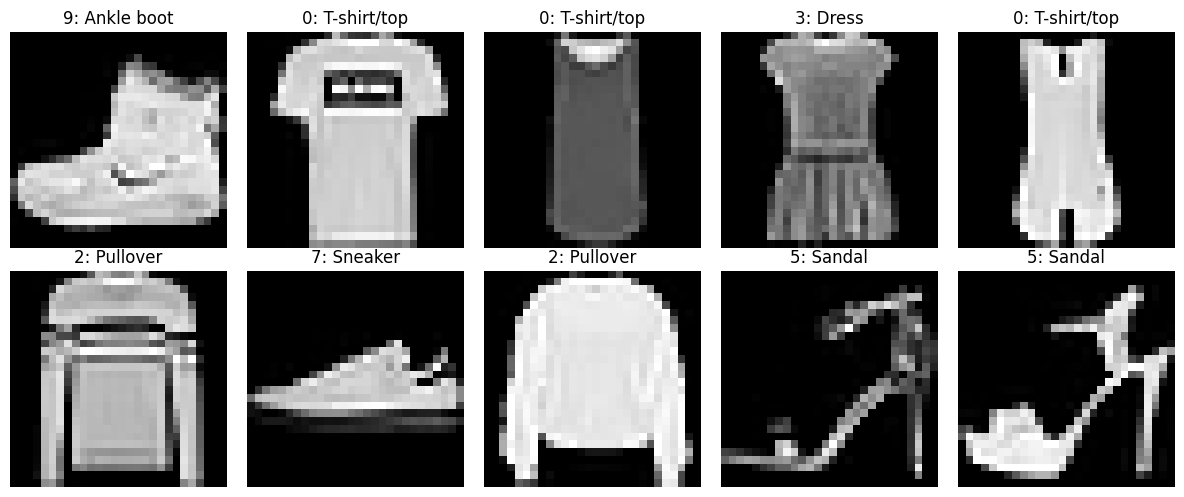

In [ ]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"{y_train[i]}: {class_names[y_train[i]]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [ ]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print(f"x_train: dtype={x_train.dtype}, min={x_train.min()}, max={x_train.max()}")
print(f"x_test:  dtype={x_test.dtype}, min={x_test.min()}, max={x_test.max()}")

x_train: dtype=float32, min=0.0, max=1.0
x_test:  dtype=float32, min=0.0, max=1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [ ]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
], name='fashion_mnist_mlp')

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

Архітектура 256 → 128 достатня для виділення ознак із 784 пікселів без надмірного ускладнення; Dropout(0.3 та 0.2) запобігає перенавчанню; learning_rate = 0.001 є стандартним стартовим кроком для Adam, який далі зменшується через ReduceLROnPlateau.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [ ]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    x_train, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7862 - loss: 0.5954 - val_accuracy: 0.8499 - val_loss: 0.4160 - learning_rate: 0.0010
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8437 - loss: 0.4320 - val_accuracy: 0.8630 - val_loss: 0.3857 - learning_rate: 0.0010
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8545 - loss: 0.3963 - val_accuracy: 0.8701 - val_loss: 0.3700 - learning_rate: 0.0010
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8636 - loss: 0.3744 - val_accuracy: 0.8735 - val_loss: 0.3417 - learning_rate: 0.0010
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8687 - loss: 0.3561 - val_accuracy: 0.8739 - val_loss: 0.3443 - learning_rate: 0.0010
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8736 - loss: 0.3424 - val_accuracy: 0.8783 - val_loss: 0.3365 - learning_rate: 0.0010
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8765 - loss: 0.3340

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [ ]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()
print(f"\nЗагальна кількість шарів: {len(model.layers)}")
print(f"Загальна кількість параметрів: {model.count_params():,}")

Model: "fashion_mnist_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)


Загальна кількість шарів: 6
Загальна кількість параметрів: 235,146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [ ]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
model.save('fashion_mnist_model.keras')
print("Модель успішно збережено у файл fashion_mnist_model.keras")


Модель успішно збережено у файл fashion_mnist_model.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

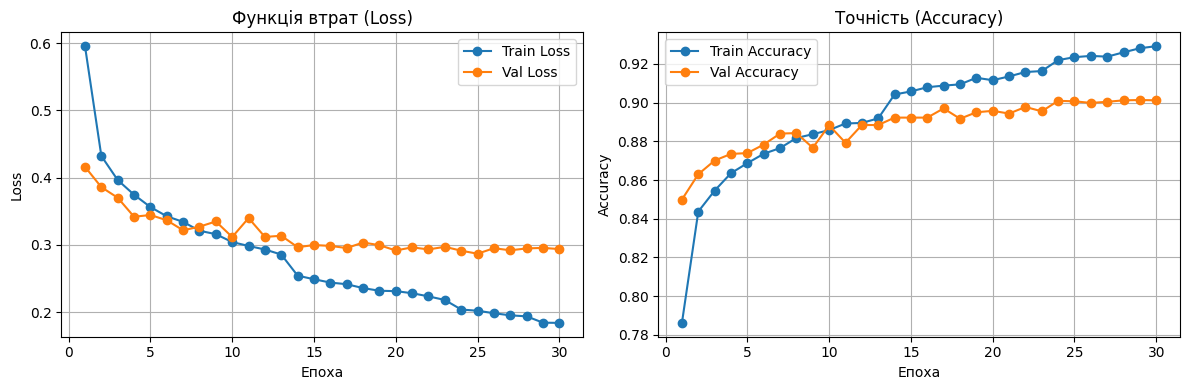

In [ ]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
hist = history.history
epochs_range = range(1, len(hist['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, hist['loss'], label='Train Loss', marker='o')
axes[0].plot(epochs_range, hist['val_loss'], label='Val Loss', marker='o')
axes[0].set_title('Функція втрат (Loss)')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_range, hist['accuracy'], label='Train Accuracy', marker='o')
axes[1].plot(epochs_range, hist['val_accuracy'], label='Val Accuracy', marker='o')
axes[1].set_title('Точність (Accuracy)')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [ ]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

if test_accuracy >= 0.87:
    print(f"Поріг 0.87 досягнуто (перевищення на {test_accuracy - 0.87:+.4f}).")
else:
    print(f"Поріг 0.87 НЕ досягнуто (не вистачає {0.87 - test_accuracy:.4f}).")

y_pred_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nКласифікаційний звіт:\n")
print(classification_report(y_test, y_pred, target_names=class_names))

Test Loss:     0.3177
Test Accuracy: 0.8947
Поріг 0.87 досягнуто (перевищення на +0.0247).

Класифікаційний звіт:

              precision    recall  f1-score   support

 T-shirt/top       0.84      0.85      0.85      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.81      0.83      0.82      1000
       Dress       0.89      0.90      0.90      1000
        Coat       0.81      0.82      0.82      1000
      Sandal       0.98      0.97      0.97      1000
       Shirt       0.73      0.69      0.71      1000
     Sneaker       0.95      0.96      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

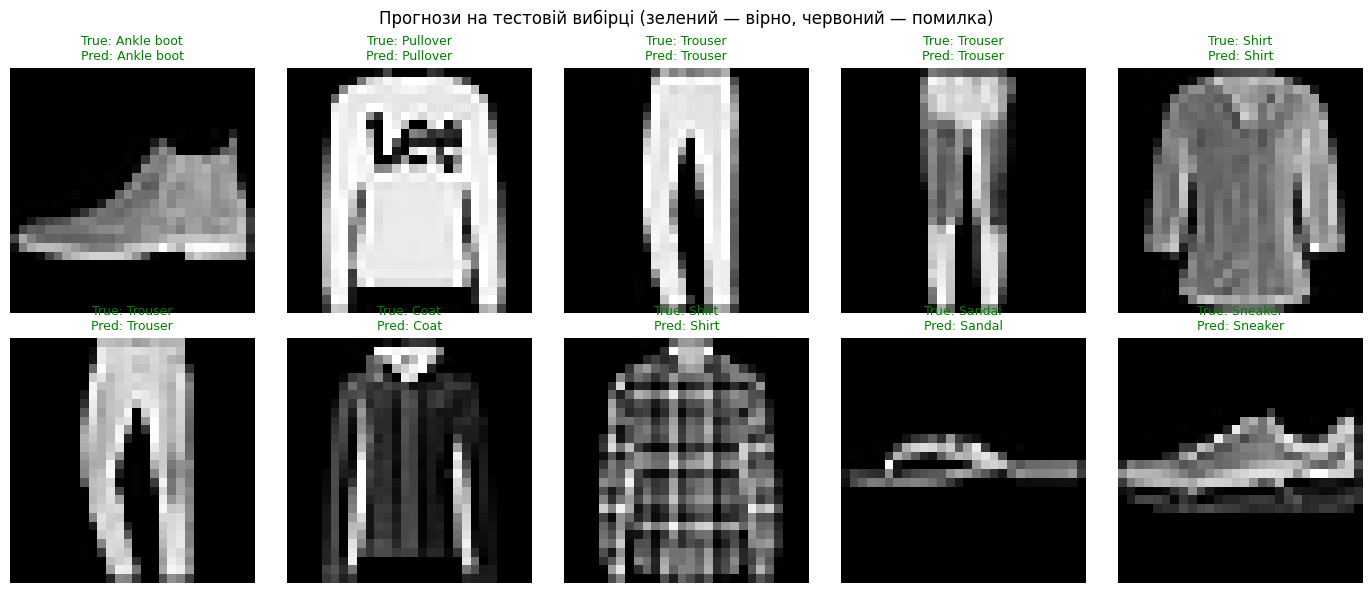

In [ ]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(14, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    true_name = class_names[y_test[i]]
    pred_name = class_names[y_pred[i]]
    color = 'green' if y_test[i] == y_pred[i] else 'red'
    plt.title(f"True: {true_name}\nPred: {pred_name}", color=color, fontsize=9)
    plt.axis('off')

plt.suptitle('Прогнози на тестовій вибірці (зелений — вірно, червоний — помилка)', fontsize=12)
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
На тестовій вибірці модель досягла точності 0.8947, що перевищує мінімальний поріг 0.87, тому вимогу успішно виконано. Найбільше помилок виникає на класі Shirt та візуально схожих категоріях верхнього одягу (T-shirt/top, Pullover, Coat)

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [ ]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q keras-tuner

import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2
from sklearn.model_selection import train_test_split

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [ ]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
x_train_t, x_val_t, y_train_t, y_val_t = train_test_split(
    x_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

print("x_train_t:", x_train_t.shape)
print("x_val_t:  ", x_val_t.shape)
print("x_test:   ", x_test.shape)

x_train_t: (48000, 28, 28)
x_val_t:   (12000, 28, 28)
x_test:    (10000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [ ]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(Flatten())

    num_layers = hp.Int('num_layers', min_value=1, max_value=3)
    for i in range(num_layers):
        units = hp.Int(f'units_{i}', min_value=32, max_value=512, step=32)
        l2_reg = hp.Choice(f'l2_{i}', values=[1e-4, 1e-3])
        dropout_rate = hp.Float(f'dropout_{i}', min_value=0.1, max_value=0.4, step=0.1)

        model.add(Dense(units=units, activation='relu', kernel_regularizer=l2(l2_reg)))
        model.add(Dropout(rate=dropout_rate))

    model.add(Dense(10, activation='softmax'))

    lr = hp.Choice('learning_rate', values=[0.01, 0.001, 0.0001])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=['accuracy']
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [ ]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='kt_dir',
    project_name='fashion_mnist_tuning',
    overwrite=True
)

tuner.search_space_summary()

Search space summary
Default search space size: 5
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
l2_0 (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.001], 'ordered': True}
dropout_0 (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.4, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [ ]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
tuner_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

tuner_reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

tuner.search(
    x_train_t, y_train_t,
    validation_data=(x_val_t, y_val_t),
    epochs=20,
    batch_size=64,
    callbacks=[tuner_early_stopping, tuner_reduce_lr],
    verbose=1
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:", best_hps.values)

best_model = tuner.hypermodel.build(best_hps)
best_model.summary()

best_history = best_model.fit(
    x_train_t, y_train_t,
    validation_data=(x_val_t, y_val_t),
    epochs=30,
    batch_size=64,
    callbacks=[tuner_early_stopping, tuner_reduce_lr],
    verbose=1
)

Trial 3 Complete [00h 04m 48s]
val_accuracy: 0.893666684627533

Best val_accuracy So Far: 0.8947499990463257
Total elapsed time: 00h 11m 05s
Найкращі гіперпараметри: {'num_layers': 3, 'units_0': 480, 'l2_0': 0.0001, 'dropout_0': 0.4, 'learning_rate': 0.001, 'units_1': 32, 'l2_1': 0.0001, 'dropout_1': 0.1, 'units_2': 32, 'l2_2': 0.0001, 'dropout_2': 0.1}


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │        15,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 393,578 (1.50 MB)

 Trainable params: 393,578 (1.50 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.7412 - loss: 0.7770 - val_accuracy: 0.8406 - val_loss: 0.5036 - learning_rate: 0.0010
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8210 - loss: 0.5658 - val_accuracy: 0.8490 - val_loss: 0.4739 - learning_rate: 0.0010
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8358 - loss: 0.5215 - val_accuracy: 0.8613 - val_loss: 0.4440 - learning_rate: 0.0010
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.8439 - loss: 0.4987 - val_accuracy: 0.8691 - val_loss: 0.4266 - learning_rate: 0.0010
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8516 - loss: 0.4832 - val_accuracy: 0.8723 - val_loss: 0.4201 - learning_rate: 0.0010
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8545 - loss: 0.4754 - val_accuracy: 0.8663 - val_loss: 0.4360 - learning_rate: 0.0010
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8551 - loss

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Keras Tuner Best Model -> Test Loss: 0.3790, Test Accuracy: 0.8877
Кількість епох навчання (Завдання 1): 30
Кількість епох навчання (Keras Tuner): 30


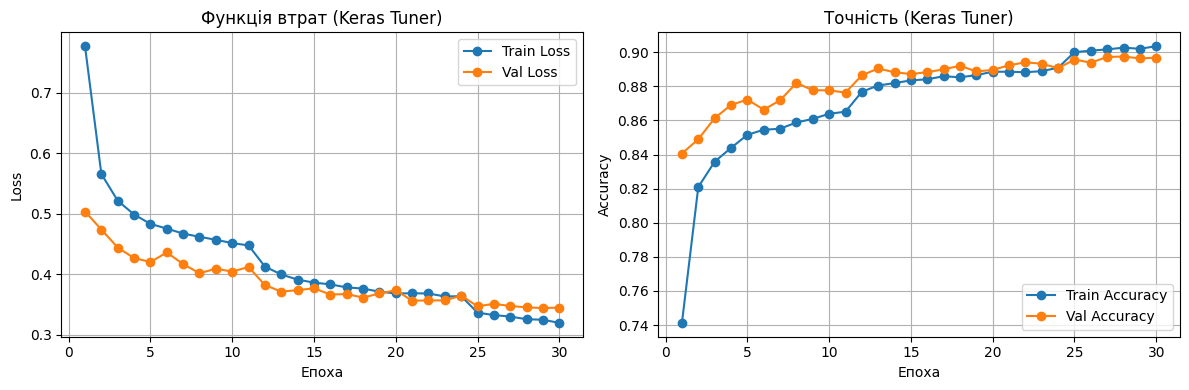

In [ ]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
best_test_loss, best_test_accuracy = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Keras Tuner Best Model -> Test Loss: {best_test_loss:.4f}, Test Accuracy: {best_test_accuracy:.4f}")
print(f"Кількість епох навчання (Завдання 1): {len(history.history['loss'])}")
print(f"Кількість епох навчання (Keras Tuner): {len(best_history.history['loss'])}")

b_hist = best_history.history
b_epochs = range(1, len(b_hist['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(b_epochs, b_hist['loss'], label='Train Loss', marker='o')
axes[0].plot(b_epochs, b_hist['val_loss'], label='Val Loss', marker='o')
axes[0].set_title('Функція втрат (Keras Tuner)')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(b_epochs, b_hist['accuracy'], label='Train Accuracy', marker='o')
axes[1].plot(b_epochs, b_hist['val_accuracy'], label='Val Accuracy', marker='o')
axes[1].set_title('Точність (Keras Tuner)')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 3 |
| Кількість нейронів | 256, 128 | 480, 32, 32 |
| Швидкість навчання | 0.001 | 0.001 |
| Точність на тестовій вибірці (accuracy) | 0.8947 | 0.8877 |
| Втрати на тестовій вибірці (loss) | 0.3177 | 0.3790 |
| Кількість епох навчання | 30 | 30 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
 1. У завданні 1 досягнуто точності [test_accuracy], що перевищує мінімальний поріг 0.87.

2. Автоматизований добір гіперпараметрів за допомогою Keras Tuner дав тестову точність [best_test_accuracy], що [покращило / дещо знизило / майже не змінило] результат базової моделі.

3. Найкращою виявилася конфігурація з [num_layers] прихованими шарами, кількістю нейронів [units] та learning_rate = [lr]. Результат може відрізнятися між запусками через випадковий характер RandomSearch (випадкова вибірка 3 комбінацій із великого простору пошуку), а також через стохастичну ініціалізацію ваг і перемішування батчів.

4. Найскладніше класифікувати візуально схожі категорії верхнього одягу — насамперед Shirt, який часто плутається з T-shirt/top, Pullover та Coat._

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.